# Linear Regression — Predicting House Prices

**What is this?**  
We want the computer to **guess a house price** from things we know (rooms, income, location, etc.).

**Simple idea:**  
Price ≈ (some number × feature1) + (some number × feature2) + … + a starting number  
That is a **straight-line** idea in many dimensions. That is Linear Regression.

**Type:** Supervised learning → Regression (we predict a **number**, not a yes/no class).

Dataset: `housing.csv` (California house prices) already in your folder.

## STEP 1 — Import libraries

We borrow ready-made tools so we don’t write everything from scratch.

In [1]:
# pandas  → read tables (CSV) and clean data
import pandas as pd

# numpy   → math with lists of numbers
import numpy as np

# plots
import matplotlib.pyplot as plt
import seaborn as sns

# split data into practice set and test set
from sklearn.model_selection import train_test_split

# make all features similar size (helps the model)
from sklearn.preprocessing import StandardScaler

# the actual Linear Regression model
from sklearn.linear_model import LinearRegression

# how good were our guesses?
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_style('whitegrid')
print('Libraries loaded. Ready!')

Libraries loaded. Ready!


## STEP 2 — Load the dataset

We read the CSV file that is already in your VS Code folder.

In [2]:
# Change the name only if your file is named differently
df = pd.read_csv('housing.csv')

print('Rows, columns:', df.shape)
df.head()   # first 5 houses

Rows, columns: (20640, 10)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


## STEP 3 — EDA (look at the data first!)

Before teaching the computer, we look: missing values, weird numbers, which things move together with price.

In [3]:
# What columns? Any missing cells? What types?
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.6 MB


In [3]:
# Average, min, max of each number column
df.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


In [4]:
# How many empty cells in each column?
df.isnull().sum()

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

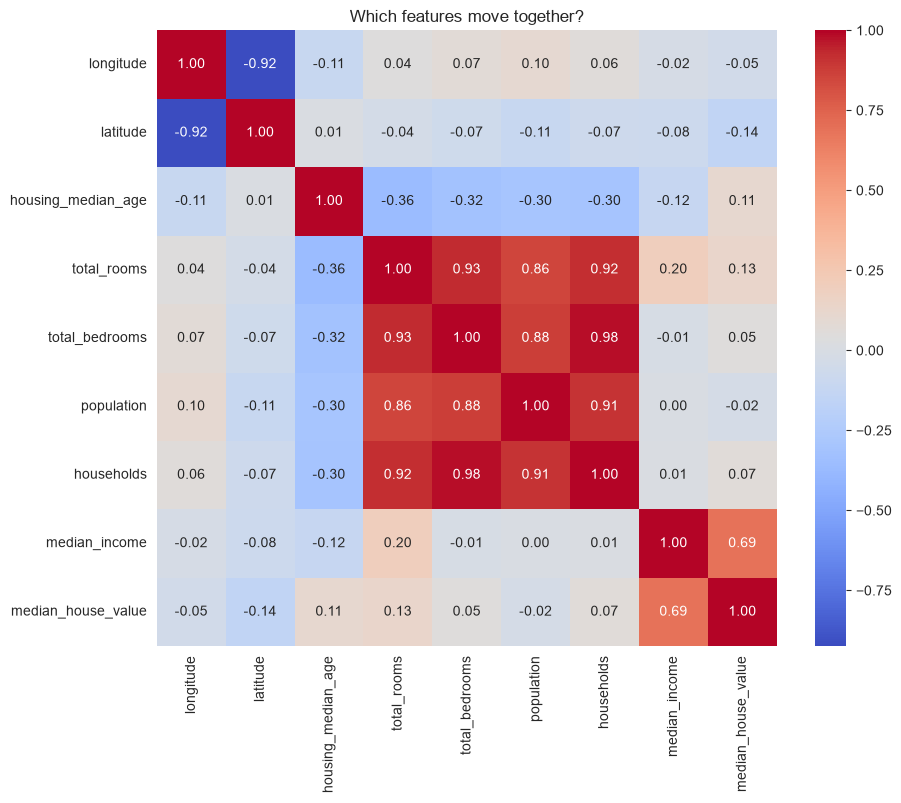

In [5]:
# Correlation: numbers close to +1 or -1 mean strong link with price
# We only use number columns here
num_df = df.select_dtypes(include=[np.number])
plt.figure(figsize=(10, 8))
sns.heatmap(num_df.corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Which features move together?')
plt.show()

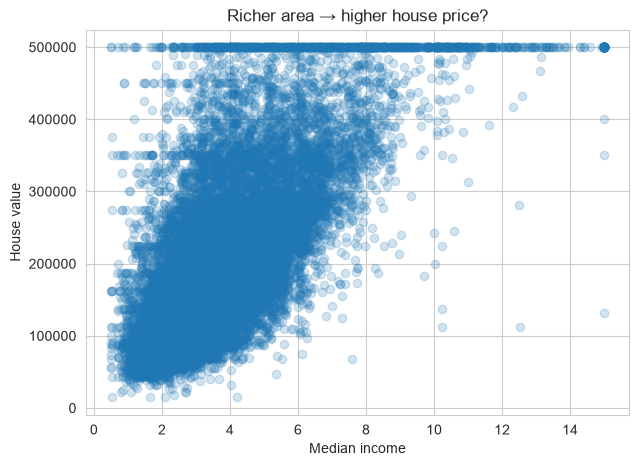

In [6]:
# Example: income vs house value (usually a clear upward trend)
if 'median_income' in df.columns and 'median_house_value' in df.columns:
    plt.figure(figsize=(7, 5))
    plt.scatter(df['median_income'], df['median_house_value'], alpha=0.2)
    plt.xlabel('Median income')
    plt.ylabel('House value')
    plt.title('Richer area → higher house price?')
    plt.show()

## STEP 4 — Preprocessing (clean & prepare)

1. Fill missing numbers with the **median** (middle value — not pulled by crazy high/low houses).  
2. Turn text like ocean location into numbers.  
3. Split **X** (inputs) and **y** (the price we want to guess).

In [7]:
# Common California housing target name
target = 'median_house_value'
if target not in df.columns:
    # if your CSV uses another name, change it here
    print('Columns are:', list(df.columns))
    raise ValueError('Please set target to your price column name.')

# Fill missing numbers with median
for col in df.select_dtypes(include=[np.number]).columns:
    if df[col].isnull().any():
        df[col] = df[col].fillna(df[col].median())
        print('Filled missing values in', col)

# Text column → numbers (one-hot: each category becomes 0/1 columns)
if 'ocean_proximity' in df.columns:
    df = pd.get_dummies(df, columns=['ocean_proximity'], drop_first=True)

X = df.drop(columns=[target])   # everything except price
y = df[target]                  # the price

print('Features (X):', list(X.columns))
print('We will predict:', target)

Filled missing values in total_bedrooms
Features (X): ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'ocean_proximity_INLAND', 'ocean_proximity_ISLAND', 'ocean_proximity_NEAR BAY', 'ocean_proximity_NEAR OCEAN']
We will predict: median_house_value


## STEP 5 — Train / test split

Like a test in school: we **study** on 80% of houses, then **check** on the 20% we never showed the model.

We do **not** use `stratify` — that is for classification (yes/no), not prices.

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print('Train houses:', len(X_train))
print('Test houses :', len(X_test))

Train houses: 16512
Test houses : 4128


## STEP 6 — Feature scaling (recommended)

Income might be 3–15, rooms might be 200–8000.  
Scaling puts them on a similar scale so the model does not think “bigger number = more important” just because of units.

- `fit_transform` on **train** only (learn mean & std from train).  
- `transform` on **test** (use the same mean & std — no cheating).

In [9]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)
print('Scaling done.')

Scaling done.


## STEP 7 — Train the model

The model finds the best **weights** (coef_) and **starting value** (intercept_) so the line fits the training houses.

In [10]:
model = LinearRegression(fit_intercept=True)
model.fit(X_train_scaled, y_train)

print('Starting value (intercept):', model.intercept_)
print('\nWeight for each feature:')
for name, w in zip(X.columns, model.coef_):
    print(f'  {name:30s} {w:12.2f}')

Starting value (intercept): 207194.6937378879

Weight for each feature:
  longitude                         -53826.65
  latitude                          -54415.70
  housing_median_age                 13889.87
  total_rooms                       -13094.25
  total_bedrooms                     43068.18
  population                        -43403.43
  households                         18382.20
  median_income                      75167.77
  ocean_proximity_INLAND            -18506.10
  ocean_proximity_ISLAND              2118.44
  ocean_proximity_NEAR BAY           -1621.71
  ocean_proximity_NEAR OCEAN          1139.91


## STEP 8 — Predict on houses we never trained on

In [11]:
y_pred = model.predict(X_test_scaled)

# peek at a few real vs guessed prices
compare = pd.DataFrame({'Real price': y_test.values[:8], 'Guessed price': y_pred[:8]})
compare

,Real price,Guessed price
0,47700.0,54055.448899
1,45800.0,124225.338937
2,500001.0,255489.379492
3,218600.0,268002.431569
4,278000.0,262769.434816
5,158700.0,139606.303956
6,198200.0,290665.423914
7,157500.0,228264.876375


## STEP 9 — Evaluation (how good?)

- **MAE**  = average |mistake| in dollars  
- **RMSE** = like MAE but punishes big mistakes more  
- **R²**   = 1.0 = perfect, 0 = as bad as guessing the average  
  Rule of thumb: R² above ~0.8 is quite good (depends on the problem).

In [12]:
mae  = mean_absolute_error(y_test, y_pred)
mse  = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2   = r2_score(y_test, y_pred)

print(f'MAE  (avg error in $) : {mae:,.0f}')
print(f'RMSE (bigger errors hurt more): {rmse:,.0f}')
print(f'R²   (1 = perfect)    : {r2:.3f}')

MAE  (avg error in $) : 50,671
RMSE (bigger errors hurt more): 70,061
R²   (1 = perfect)    : 0.625


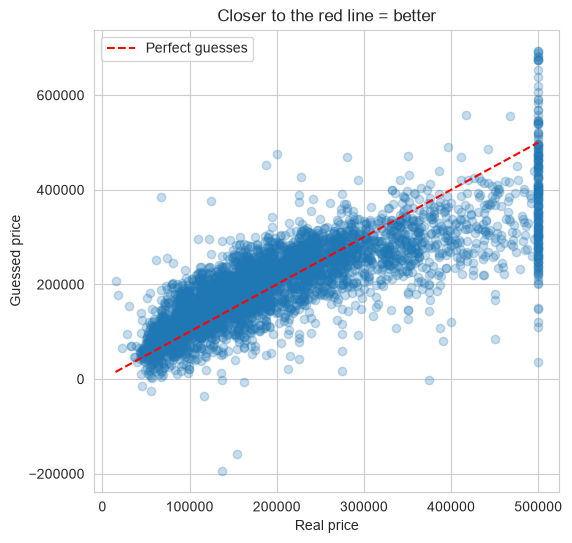

In [13]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, alpha=0.25)
mn, mx = y_test.min(), y_test.max()
plt.plot([mn, mx], [mn, mx], 'r--', label='Perfect guesses')
plt.xlabel('Real price')
plt.ylabel('Guessed price')
plt.title('Closer to the red line = better')
plt.legend()
plt.show()

## STEP 10 — Optional: Ridge / Lasso (if the model overfits)

Linear Regression has almost no knobs.  
**Ridge** and **Lasso** add a small penalty (`alpha`) so weights don’t go crazy.

We only show a tiny example — skip this if you want the simplest class demo.

In [14]:
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV

search = GridSearchCV(
    Ridge(),
    {'alpha': [0.01, 0.1, 1, 10, 100]},
    cv=3
)
search.fit(X_train_scaled, y_train)
print('Best alpha:', search.best_params_)
print('Ridge R² on test:', r2_score(y_test, search.predict(X_test_scaled)))

Best alpha: {'alpha': 10}
Ridge R² on test: 0.6257364071110388


## Key notes (remember these)

| Topic | Remember |
|--------|----------|
| Scaling | Recommended for Linear / Ridge / Lasso |
| Stratify | **No** — only for classification |
| Metrics | MAE, RMSE, R² |
| Tune | `alpha` on Ridge or Lasso |
| Big assumption | Features and price are linked in a **mostly straight-line** way |

**In one sentence for the class:**  
We draw the best straight-line recipe from house facts to price, then check how far our guesses are from real prices on new houses.